# 04 · Predicting purchase from a session's first 5 events
Sessions with at least 6 events. Features use only the first 5 events plus the user's earlier
sessions; the label is a purchase later in the session. Sessions that already bought within the
first 5 events are dropped. Split by time: train Oct 1–17, validation Oct 18–21, test Oct 22–31.

Role in the project: (1) an independent check on notebook 02. If prior purchases dominate the model,
that corroborates the first-time buyer gap. (2) A propensity score for the experiment. It is used for
a pre-registered heterogeneity analysis, which asks whether the in-cart message helps low-propensity
first-time shoppers most. It is not used to decide who gets treated.

In [1]:
import json, os
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = os.environ.get("FUNNEL_DB", ROOT / "data/processed/funnel.duckdb")
FIG = ROOT / "outputs/figures"
RESULTS = ROOT / "outputs/results.json"
con = duckdb.connect(str(DB), read_only=True)
results = json.loads(RESULTS.read_text())
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
df = con.sql("""
WITH ev AS (
    SELECT e.*, t.price_tier,
        row_number() OVER (PARTITION BY session_id ORDER BY event_time, ev_id) AS k,
        count(*) OVER (PARTITION BY session_id) AS n_ev
    FROM events_s e JOIN product_tiers t USING (product_id)
), sess AS (
    SELECT session_id, user_id, min(event_time) AS start,
        max(CASE WHEN event_type = 'cart' THEN 1 ELSE 0 END) AS had_cart,
        max(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END) AS had_purchase
    FROM events_s GROUP BY ALL
), hist AS (
    SELECT session_id,
        row_number() OVER w - 1 AS prior_sessions,
        coalesce(sum(had_cart) OVER (w ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING), 0) AS prior_cart_sessions,
        coalesce(sum(had_purchase) OVER (w ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING), 0) AS prior_purchase_sessions,
        coalesce(epoch(start) - epoch(lag(start) OVER w), -1) AS secs_since_prev_session
    FROM sess WINDOW w AS (PARTITION BY user_id ORDER BY start)
), first5 AS (
    SELECT session_id, min(event_time) AS start,
        count(*) FILTER (WHERE event_type = 'view') AS n_view,
        count(*) FILTER (WHERE event_type = 'cart') AS n_cart,
        count(*) FILTER (WHERE event_type = 'purchase') AS n_purchase_early,
        count(DISTINCT product_id) AS n_products,
        count(DISTINCT category) AS n_categories,
        count(DISTINCT brand) AS n_brands,
        round(avg(price), 4) AS mean_price, max(price) AS max_price, min(price) AS min_price,
        arg_max(price, k) AS last_price,
        round(avg(price_tier), 4) AS mean_tier,
        epoch(max(event_time)) - epoch(min(event_time)) AS secs_first5,
        mode(category) AS main_category
    FROM ev WHERE k <= 5 AND n_ev >= 6 GROUP BY session_id
), label AS (
    SELECT session_id, max(CASE WHEN event_type = 'purchase' AND k > 5 THEN 1 ELSE 0 END) AS y
    FROM ev WHERE n_ev >= 6 GROUP BY session_id
)
SELECT f.*, h.* EXCLUDE (session_id), l.y
FROM first5 f JOIN hist h USING (session_id) JOIN label l USING (session_id)
WHERE f.n_purchase_early = 0
""").df()
df = df.sort_values("session_id", ignore_index=True)  # DuckDB row order is not fixed
df["hour"] = df.start.dt.hour
df["weekday"] = df.start.dt.weekday
print(f"{len(df):,} sessions, base rate {df.y.mean():.2%}")

209,302 sessions, base rate 10.01%


In [3]:
top_cats = df.main_category.value_counts().index[:10]
X = pd.get_dummies(df.main_category.where(df.main_category.isin(top_cats), "other"), prefix="cat", dtype=int)
features = ["n_view", "n_cart", "n_products", "n_categories", "n_brands", "mean_price", "max_price", "min_price",
            "last_price", "mean_tier", "secs_first5", "prior_sessions", "prior_cart_sessions",
            "prior_purchase_sessions", "secs_since_prev_session", "hour", "weekday"]
X = pd.concat([df[features], X], axis=1)
y = df.y
day = df.start.dt.day
train, valid, test = day <= 17, (day >= 18) & (day <= 21), day >= 22
print({k: (int(m.sum()), round(y[m].mean(), 4)) for k, m in [("train", train), ("valid", valid), ("test", test)]})

{'train': (115489, np.float64(0.0993)), 'valid': (28622, np.float64(0.1066)), 'test': (65191, np.float64(0.0986))}


In [4]:
model = xgb.XGBClassifier(n_estimators=2000, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                          min_child_weight=5, eval_metric="aucpr", early_stopping_rounds=100, n_jobs=-1, random_state=0)
model.fit(X[train], y[train], eval_set=[(X[valid], y[valid])], verbose=False)
p = model.predict_proba(X[test])[:, 1]
pr_auc, roc = average_precision_score(y[test], p), roc_auc_score(y[test], p)
base = y[test].mean()
top_decile = y[test][p >= np.quantile(p, 0.9)].mean()
results["model"] = {"n_sessions": len(df), "n_test": int(test.sum()), "test_base_rate": round(base, 4),
                    "pr_auc": round(pr_auc, 4), "roc_auc": round(roc, 4), "best_iteration": int(model.best_iteration),
                    "top_decile_precision": round(top_decile, 4), "top_decile_lift": round(top_decile / base, 2)}
print(results["model"])

{'n_sessions': 209302, 'n_test': 65191, 'test_base_rate': np.float64(0.0986), 'pr_auc': 0.3864, 'roc_auc': 0.7852, 'best_iteration': 120, 'top_decile_precision': np.float64(0.4087), 'top_decile_lift': np.float64(4.15)}


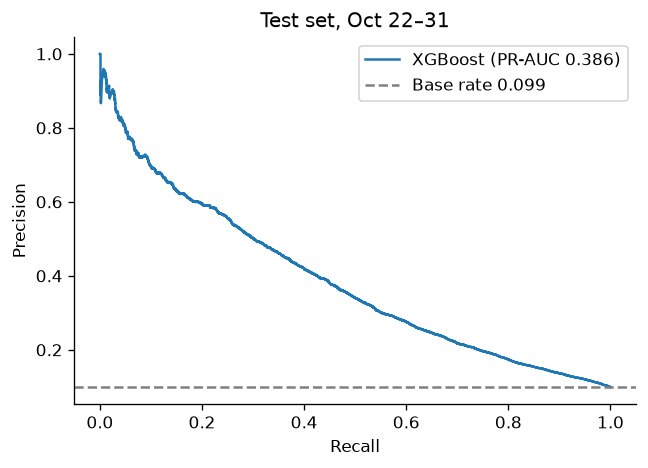

In [5]:
prec, rec, _ = precision_recall_curve(y[test], p)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(rec, prec, label=f"XGBoost (PR-AUC {pr_auc:.3f})")
ax.axhline(base, ls="--", c="grey", label=f"Base rate {base:.3f}")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Test set, Oct 22–31"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "pr_curve.png"); plt.show()

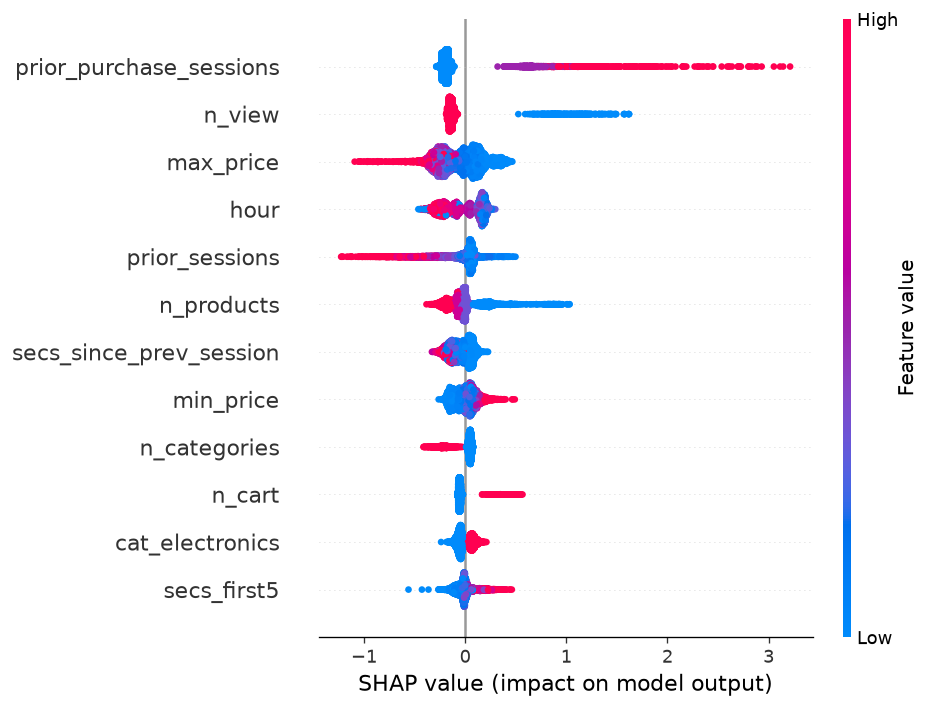

prior_purchase_sessions    0.327674
n_view                     0.194881
max_price                  0.184350
hour                       0.168905
prior_sessions             0.144024
n_products                 0.122735
secs_since_prev_session    0.088065
min_price                  0.087230
n_categories               0.081310
n_cart                     0.073217
dtype: float32

In [6]:
Xs = X[test].sample(min(5000, int(test.sum())), random_state=0)
sv = shap.TreeExplainer(model).shap_values(Xs)
mean_abs = pd.Series(np.abs(sv).mean(0), index=Xs.columns).sort_values(ascending=False)
results["model"]["top_features"] = mean_abs.head(6).round(4).to_dict()
shap.summary_plot(sv, Xs, max_display=12, show=False)
plt.gcf().set_size_inches(8, 6); plt.tight_layout(); plt.savefig(FIG / "shap_summary.png", dpi=120); plt.show()
mean_abs.head(10)

## Does the model still rank shoppers within the experiment's population?
Test sessions from users with no earlier purchase and with an electronics-led first 5 events.
If the score separates buyers there too, its terciles are meaningful strata for the experiment readout.

In [7]:
seg_mask = (df.prior_purchase_sessions[test] == 0) & (df.main_category[test] == "electronics")
ys, ps = y[test][seg_mask.values], p[seg_mask.values]
tercile = pd.qcut(ps, 3, labels=["low", "mid", "high"])
by_tercile = pd.Series(ys.values).groupby(tercile, observed=True).mean()
results["model"]["target_population"] = {
    "n_test_sessions": int(seg_mask.sum()), "base_rate": round(ys.mean(), 4),
    "pr_auc": round(average_precision_score(ys, ps), 4), "roc_auc": round(roc_auc_score(ys, ps), 4),
    "purchase_rate_by_score_tercile": by_tercile.round(4).to_dict()}
print(results["model"]["target_population"])

{'n_test_sessions': 20832, 'base_rate': np.float64(0.0986), 'pr_auc': 0.3457, 'roc_auc': 0.7639, 'purchase_rate_by_score_tercile': {'low': 0.0338, 'mid': 0.0593, 'high': 0.2028}}


In [8]:
RESULTS.write_text(json.dumps(results, indent=2, default=float))

9432